# Galaxy Zoo 2: Exploratory Data Analysis

Galaxy Zoo 2 asked volunteers to classify SDSS galaxy images by walking down a decision
tree of 10 questions. Each galaxy comes with the number of votes for every answer, and the task is to predict the **vote fractions** for all 30 answers at once.

This notebook looks at what the labels actually contain. The main finding is that vote
depth collapses down the tree: the first question gets ~40 votes per galaxy, the deepest
ones only 2-4, which limits how well any model can do on them.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src import data, eda
from src.dataset import load_splits
from src.transforms import test_transform, train_transform

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
SPLIT_COLORS = {"train": "#4C72B0", "val": "#1BAF7A", "test": "#DD8452"}

## Dataset and label schema

The HuggingFace dataset `mwalmsley/gz2` has a train and a test split. A fixed 20% of the
train split (seed 42) is held out for validation and early stopping.

In [2]:
train, val, test = load_splits()
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,}")

pd.DataFrame(
    {
        "question": data.QUESTION_NAMES,
        "answers": [", ".join(answers) for _, answers in data.QUESTIONS],
        "outputs": [f"{sl.start}-{sl.stop - 1}" for sl in data.QUESTION_SLICES],
    },
    index=[f"Q{q}" for q in range(1, len(data.QUESTIONS) + 1)],
)

train 137,901 | val 34,476 | test 18,797


,question,answers,outputs
Q1,smooth-or-featured,"smooth, featured-or-disk, artifact",0-2
Q2,disk-edge-on,"yes, no",3-4
Q3,has-spiral-arms,"yes, no",5-6
Q4,bar,"yes, no",7-8
Q5,bulge-size,"dominant, obvious, just-noticeable, no",9-12
Q6,something-odd,"yes, no",13-14
Q7,how-rounded,"round, in-between, cigar",15-17
Q8,bulge-shape,"round, boxy, no-bulge",18-20
Q9,spiral-winding,"tight, medium, loose",21-23
Q10,spiral-arm-count,"1, 2, 3, 4, more-than-4, cant-tell",24-29


## Example galaxies

Galaxies with a clear majority (> 80% of at least 20 votes) for a few typical answers.
Images are 424×424 px, centred on the galaxy.

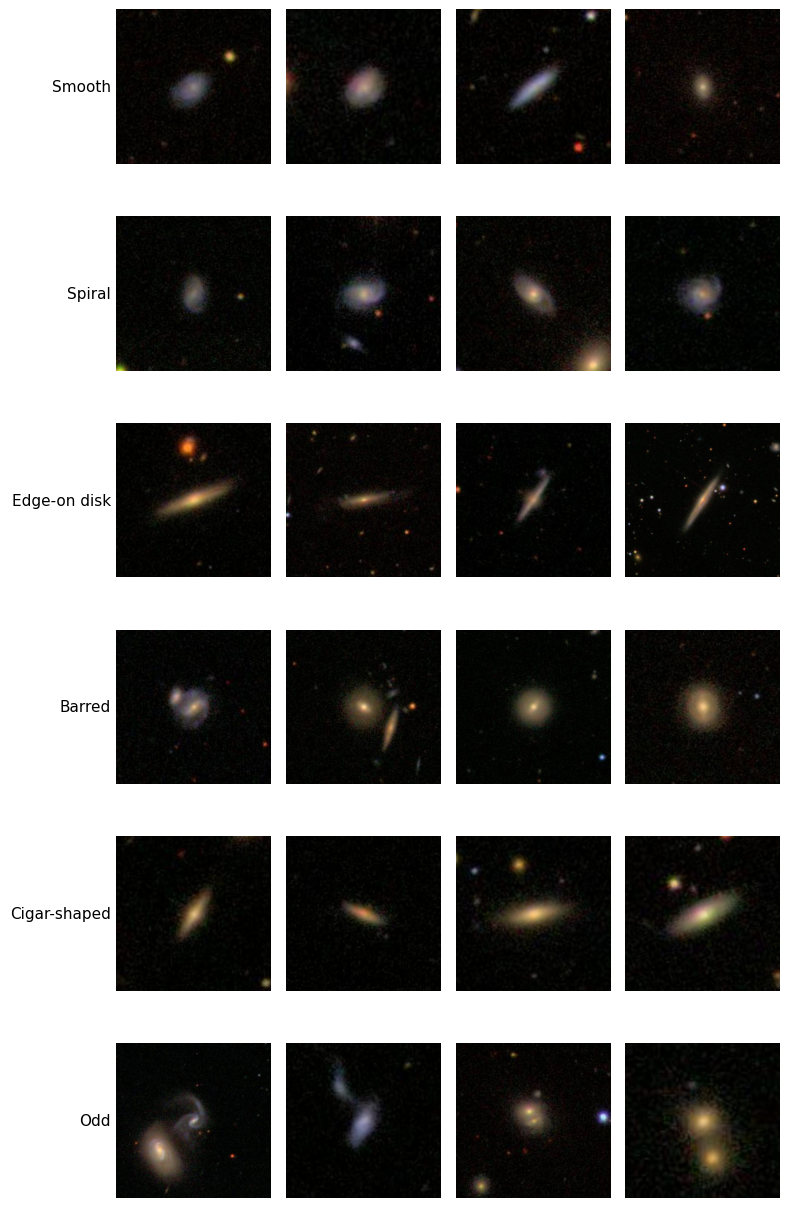

In [3]:
votes = eda.question_votes(train)
fracs = eda.fractions(train)

examples = {
    "Smooth": ("smooth-or-featured_smooth", "smooth-or-featured"),
    "Spiral": ("has-spiral-arms_yes", "has-spiral-arms"),
    "Edge-on disk": ("disk-edge-on_yes", "disk-edge-on"),
    "Barred": ("bar_yes", "bar"),
    "Cigar-shaped": ("how-rounded_cigar", "how-rounded"),
    "Odd": ("something-odd_yes", "something-odd"),
}

rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(examples), 4, figsize=(8, 2.1 * len(examples)))
for row, (label, (answer, question)) in zip(axes, examples.items(), strict=True):
    candidates = np.flatnonzero((fracs[answer] > 0.8) & (votes[question] >= 20))
    for ax, i in zip(row, rng.choice(candidates, len(row), replace=False), strict=True):
        ax.imshow(train[int(i)]["image"])
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    row[0].set_ylabel(label, rotation=0, ha="right", va="center", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "galaxy_examples.jpg", dpi=150, bbox_inches="tight")
plt.show()

## Vote depth collapses down the decision tree

Only galaxies that reach a question in the tree get votes on it, and among those the
number of votes `N` falls sharply with depth. A fraction from a single vote is 0 or 1 by
construction and carries no information about how uncertain the answer is.

In [4]:
def depth_summary(votes: pd.DataFrame) -> pd.DataFrame:
    rows = {}
    for q, name in enumerate(data.QUESTION_NAMES, start=1):
        n = votes[name]
        reached = n[n > 0]
        rows[f"Q{q} {name}"] = {
            "reached, N>0 [%]": 100 * (n > 0).mean(),
            "reached, N>=5 [%]": 100 * (n >= 5).mean(),
            "median N": reached.median(),
            "labels from 1 vote [%]": 100 * (reached == 1).mean(),
        }
    return pd.DataFrame(rows).T.round(1)


depth_summary(votes)

,"reached, N>0 [%]","reached, N>=5 [%]",median N,labels from 1 vote [%]
Q1 smooth-or-featured,100.0,100.0,43.0,0.0
Q2 disk-edge-on,98.6,69.8,8.0,4.3
Q3 has-spiral-arms,95.2,55.9,6.0,8.4
Q4 bar,95.2,55.9,6.0,8.4
Q5 bulge-size,95.2,55.9,6.0,8.4
Q6 something-odd,100.0,100.0,41.0,0.0
Q7 how-rounded,97.5,91.0,33.0,2.2
Q8 bulge-shape,47.9,14.1,2.0,40.6
Q9 spiral-winding,58.3,28.7,4.0,27.9
Q10 spiral-arm-count,58.3,28.7,4.0,27.9


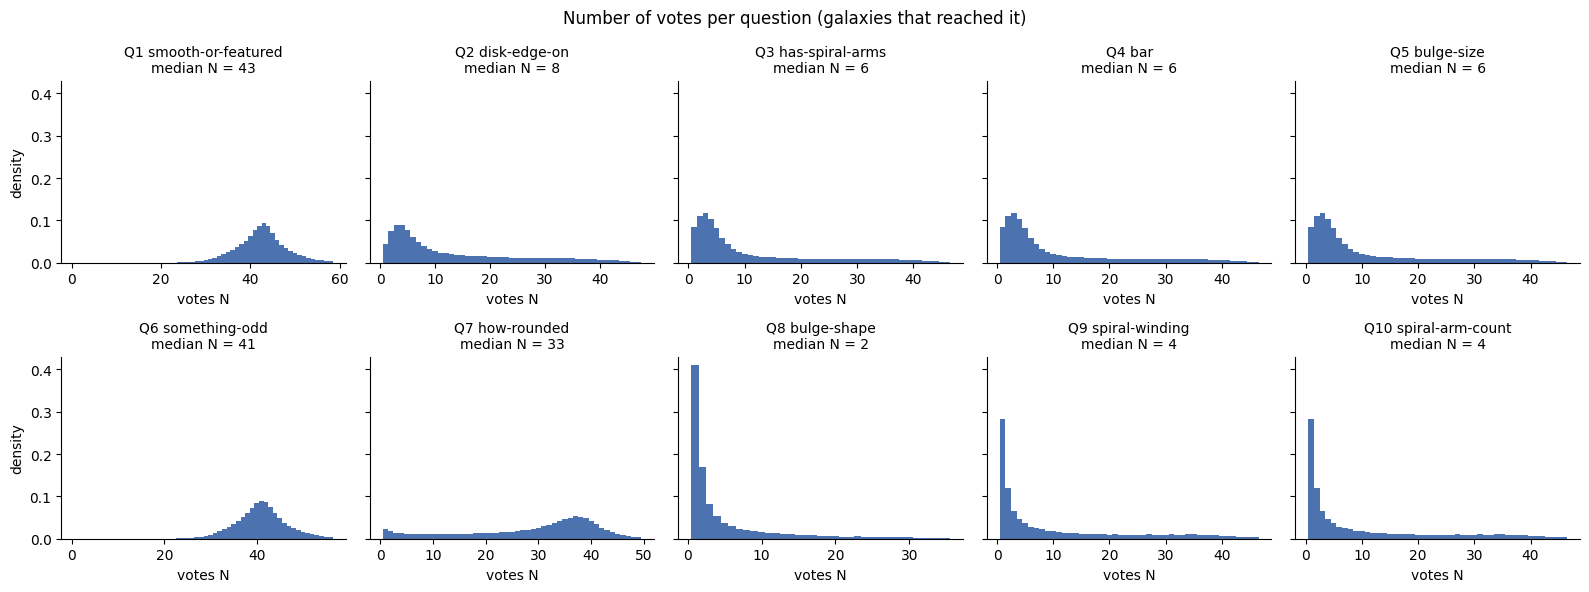

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharey=True)
for ax, (q, name) in zip(axes.flat, enumerate(data.QUESTION_NAMES, start=1), strict=True):
    n = votes[name]
    n = n[n > 0]
    hi = int(n.quantile(0.99))
    ax.hist(n, bins=np.arange(0.5, hi + 1.5), density=True, color=SPLIT_COLORS["train"])
    ax.set_title(f"Q{q} {name}\nmedian N = {n.median():.0f}", fontsize=10)
    ax.set_xlabel("votes N")
axes[0, 0].set_ylabel("density")
axes[1, 0].set_ylabel("density")
fig.suptitle("Number of votes per question (galaxies that reached it)")
fig.tight_layout()
fig.savefig(FIG_DIR / "vote_depth.png", dpi=150, bbox_inches="tight")
plt.show()

## Class imbalance

Share of galaxies whose majority-vote answer is each option, among galaxies that reached
the question. This is the label that accuracy and F1 are computed on. The rare answers
deep in the tree (`boxy` bulges in Q8, 3, 4 or more spiral arms in Q10) are the hardest
to predict.

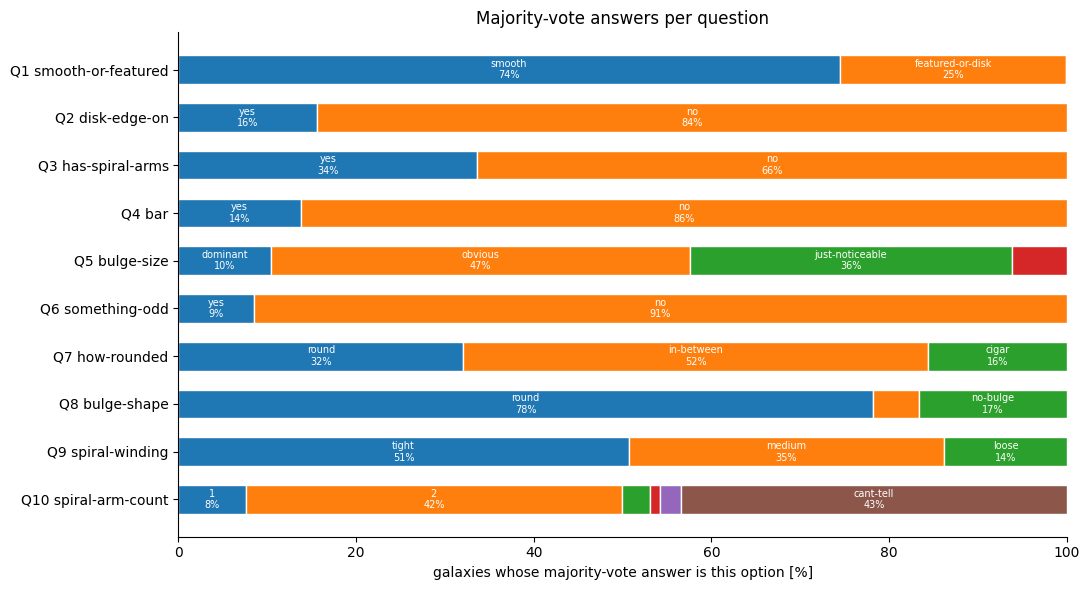

,rarest answer,share [%]
Q1 smooth-or-featured,artifact,0.1
Q2 disk-edge-on,yes,15.6
Q3 has-spiral-arms,yes,33.6
Q4 bar,yes,13.8
Q5 bulge-size,no,6.2
Q6 something-odd,yes,8.5
Q7 how-rounded,cigar,15.6
Q8 bulge-shape,boxy,5.2
Q9 spiral-winding,loose,13.8
Q10 spiral-arm-count,4,1.2


In [6]:
shares = {}
questions = zip(data.QUESTIONS, data.QUESTION_SLICES, strict=True)
for q, ((name, answers), sl) in enumerate(questions, start=1):
    reached = votes[name] > 0
    majority = fracs.iloc[:, sl][reached].to_numpy().argmax(axis=1)
    counts = np.bincount(majority, minlength=len(answers))
    shares[f"Q{q} {name}"] = dict(zip(answers, 100 * counts / reached.sum(), strict=True))

palette = plt.get_cmap("tab10").colors
fig, ax = plt.subplots(figsize=(11, 6))
for y, (_, answer_shares) in enumerate(reversed(shares.items())):
    left = 0.0
    for i, (answer, share) in enumerate(answer_shares.items()):
        ax.barh(y, share, left=left, color=palette[i], edgecolor="white", height=0.6)
        if share >= 7:
            ax.text(left + share / 2, y, f"{answer}\n{share:.0f}%",
                    ha="center", va="center", fontsize=7, color="white")
        left += share
ax.set_yticks(range(len(shares)))
ax.set_yticklabels(list(reversed(shares)))
ax.set_xlim(0, 100)
ax.set_xlabel("galaxies whose majority-vote answer is this option [%]")
ax.set_title("Majority-vote answers per question")
fig.tight_layout()
fig.savefig(FIG_DIR / "class_imbalance.png", dpi=150, bbox_inches="tight")
plt.show()

rarest = {q: min(s.items(), key=lambda kv: kv[1]) for q, s in shares.items()}
pd.DataFrame(
    {
        "rarest answer": [a for a, _ in rarest.values()],
        "share [%]": [v for _, v in rarest.values()],
    },
    index=list(rarest),
).round(1)

## Fractions in the first question

Votes on Q1 are deep (median 43), so its fractions are smooth and mostly polarised:
volunteers tend to agree that a galaxy is either smooth or featured.

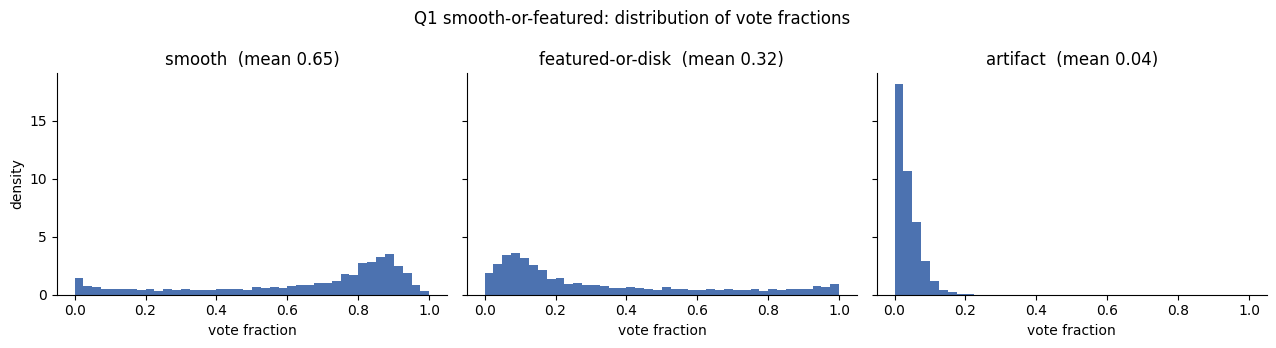

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, answer in zip(axes, data.QUESTIONS[0][1], strict=True):
    f = fracs[f"smooth-or-featured_{answer}"].dropna()
    ax.hist(f, bins=np.linspace(0, 1, 41), density=True, color=SPLIT_COLORS["train"])
    ax.set_title(f"{answer}  (mean {f.mean():.2f})")
    ax.set_xlabel("vote fraction")
axes[0].set_ylabel("density")
fig.suptitle("Q1 smooth-or-featured: distribution of vote fractions")
fig.tight_layout()
plt.show()

## Train, validation and test splits consistency

Mean vote fraction of every answer in each split, over galaxies that reached the question.

In [8]:
splits = {"train": train, "val": val, "test": test}
split_votes = {"train": votes} | {s: eda.question_votes(splits[s]) for s in ("val", "test")}
split_fracs = {"train": fracs} | {s: eda.fractions(splits[s]) for s in ("val", "test")}

means = {}
for (name, _), sl in zip(data.QUESTIONS, data.QUESTION_SLICES, strict=True):
    for key in data.ANSWER_KEYS[sl]:
        means[key] = {
            s: split_fracs[s][key][split_votes[s][name] > 0].mean() for s in splits
        }
means = pd.DataFrame(means).T
means["max difference"] = means.max(axis=1) - means.min(axis=1)
print(f"largest difference in a mean fraction between splits: {means['max difference'].max():.4f}")
means.round(3)

largest difference in a mean fraction between splits: 0.0098


,train,val,test,max difference
smooth-or-featured_smooth,0.645,0.647,0.645,0.002
smooth-or-featured_featured-or-disk,0.317,0.316,0.319,0.004
smooth-or-featured_artifact,0.037,0.037,0.035,0.002
disk-edge-on_yes,0.176,0.175,0.173,0.002
disk-edge-on_no,0.824,0.825,0.827,0.002
has-spiral-arms_yes,0.335,0.332,0.334,0.003
has-spiral-arms_no,0.665,0.668,0.666,0.003
bar_yes,0.174,0.173,0.175,0.001
bar_no,0.826,0.827,0.825,0.001
bulge-size_dominant,0.115,0.113,0.108,0.007


## Augmentation

During training every image is rotated by a random angle, centre-cropped to 224×224,
randomly flipped and jittered in brightness and contrast. Rotating the full 424×424 image
before cropping keeps the black corners created by the rotation out of the crop.
Evaluation uses only the centre crop.

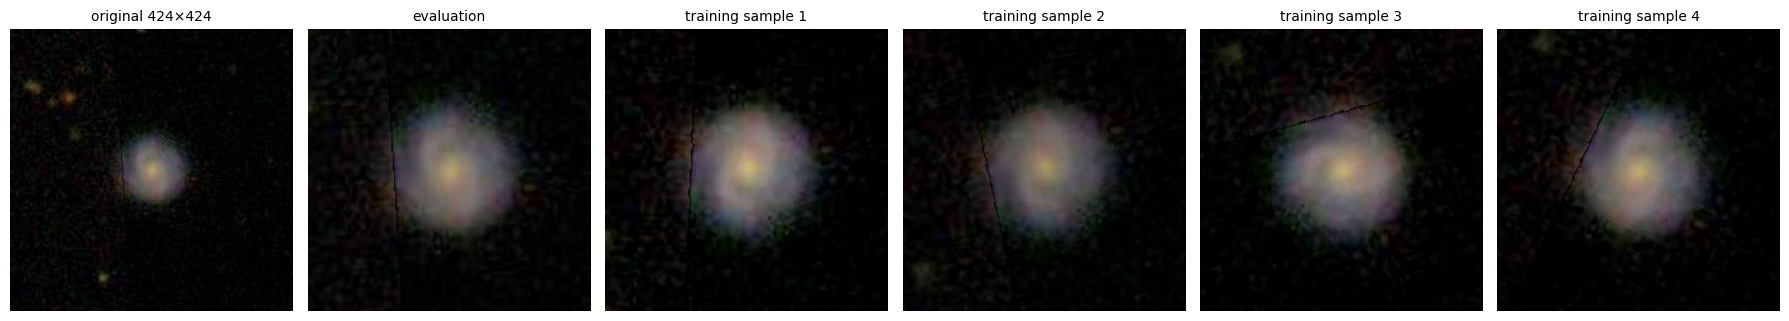

In [9]:
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def to_display(t: torch.Tensor) -> np.ndarray:
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


spiral = np.flatnonzero((fracs["has-spiral-arms_yes"] > 0.9) & (votes["has-spiral-arms"] >= 20))
image = train[int(spiral[0])]["image"]

torch.manual_seed(0)
panels = [
    ("original 424×424", np.asarray(image)),
    ("evaluation", to_display(test_transform(image))),
]
panels += [(f"training sample {i}", to_display(train_transform(image))) for i in range(1, 5)]

fig, axes = plt.subplots(1, len(panels), figsize=(3 * len(panels), 3.2))
for ax, (title, img) in zip(axes, panels, strict=True):
    ax.imshow(img)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
fig.tight_layout()
plt.show()

## Summary

- The first questions of the tree (Q1, Q6, Q7) are answered for almost every galaxy with
  30-40 votes; the deep questions (Q8-Q10) are reached by about half of the galaxies and
  get only 2-4 votes, often a single one.
- The deep questions are also the most imbalanced: `boxy` bulges are 5% of the galaxies
  that reach Q8, and 3, 4 or more spiral arms only 1-3% of those that reach Q10.
- The splits are consistent, so differences between validation and test results are not
  caused by a shift in the label distribution.

Together this predicts the pattern seen in the benchmark: models do well on the top of the
tree and poorly on Q8-Q10, regardless of architecture.